# Quantum annealing evolution: bath relaxation and local SEAQT

An open-system model for quantum annealing: a qubit register coupled to a
fixed-temperature bath, driven by the real D-Wave QPU annealing
Hamiltonian. This notebook walks through the physics, validates it live,
and builds up from 1 qubit to 2 coupled qubits, using **two** dissipators:

1. **`bath_dissipator`** (sections 1-4) -- the whole composite system
   relaxes toward a single global Gibbs state.
2. **`local_seaqt_dissipator`** (sections 6-9) -- from Yamada, Kusaba,
   Li, von Spakovsky et al., arXiv:2404.05473v3 (eqs. 6, 7, 15); each
   qubit relaxes *locally*, coupled to the other only through their
   current reduced states.

**Physics common to both**

$$\dot\rho\big|_{\text{unitary}} = -\frac{i}{\hbar}[H(t), \rho]$$

with the D-Wave QPU Hamiltonian

$$H(s) = -\frac{A(s)}{2}\sum_i \sigma_x^{(i)} + \frac{B(s)}{2}\Big(\sum_i h_i \sigma_z^{(i)} + \sum_{i<j} J_{ij}\sigma_z^{(i)}\sigma_z^{(j)}\Big)$$

$A(s), B(s)$ read from the real QPU datasheet, $s=t/t_{\text{anneal}}\in[0,1]$.

**`bath_dissipator`** relaxes $\rho$ toward the Gibbs (canonical) state
$e^{-\beta H}/Z$ at bath inverse temperature $\beta$:

$$\dot\rho\big|_{\text{diss}} = -\frac{\beta}{2\tau}\{F(\rho,H,\beta),\rho\},
  \qquad F = (H-\langle H\rangle_\rho I) - \tfrac{1}{\beta}(S_{\mathrm{op}}-\langle S_{\mathrm{op}}\rangle_\rho I)$$

with $S_{\mathrm{op}}=-\ln\rho$. Both bracketed terms are "fluctuation
operators" with zero expectation in $\rho$ by construction, which is what
guarantees trace conservation with no extra projection step. Its 2nd-law
equivalent: the free energy $\Omega(\rho)=\langle H\rangle_\rho - S(\rho)/\beta$
decreases monotonically to its minimum at the Gibbs state.

**`local_seaqt_dissipator`** relaxes each qubit $J\in\{A,B\}$ locally:

$$\dot\rho\big|_{\text{diss}} = -\tfrac{1}{\tau_A} D_A\otimes\rho_B - \tfrac{1}{\tau_B}\rho_A\otimes D_B,
  \qquad D_J = \rho_J\ln\rho_J - \beta_R\langle f\rangle_J\rho_J + \tfrac{1}{2}\beta_R\{H_J,\rho_J\}$$

with $\rho_A=\mathrm{Tr}_B(\rho)$, $H_J$ the "locally perceived" Hamiltonian
(traced over the other qubit, weighted by its current state). `Tr(D_J)=0`
exactly by construction (see section 9), but **positivity of $\rho$ is not
guaranteed** for this one -- see section 9.

See `README.md` for the full derivation and sign/unit conventions.

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt

REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

from seaqt import bath_dissipator, entropy, evolve, free_energy, free_energy_operator, gibbs_state, hermitize, population_distribution
from seaqt.local_seaqt import local_seaqt_dissipator, locally_perceived_operator, reduced_state, _subsystem_dissipator
from seaqt.operators import basis_labels, ising_hamiltonian, sigma_x, sigma_z
from seaqt.dwave import load_schedule, hamiltonian_1qubit, hamiltonian_nqubit, beta_from_kelvin

SCHEDULE_PATH = (
    r"C:\Users\andre\OneDrive\Documentos\Maestría\Julich\codigos"
    r"\09-1265A-C_Advantage_system5_3_annealing_schedule.xlsx"
)

plt.rcParams["figure.dpi"] = 110
np.set_printoptions(precision=4, suppress=True)
print("Setup OK.")

Setup OK.


## 1. Physics validation, live

Rather than just trusting the tests, compute the dissipator directly and
check the invariants it claims to satisfy: trace conservation, and that it
vanishes exactly at the Gibbs equilibrium state.

In [2]:
H_demo = 0.5 * sigma_z + 0.3 * sigma_x
beta_demo = 1.5

rho_eq = gibbs_state(H_demo, beta_demo)
D_at_eq = bath_dissipator(rho_eq, H_demo, beta_demo, tau=1.0)
print("Dissipator at the Gibbs state (should be ~0):")
print(D_at_eq)
print(f"max|D| = {np.max(np.abs(D_at_eq)):.3e}")

rho_away = np.array([[0.6, 0.15 - 0.1j], [0.15 + 0.1j, 0.4]], dtype=complex)
D_away = bath_dissipator(rho_away, H_demo, beta_demo, tau=1.0)
print(f"\nAway from equilibrium, max|D| = {np.max(np.abs(D_away)):.3e} (nonzero, as expected)")
print(f"Tr(D)   = {np.trace(D_away):.3e}  (want 0)")

Dissipator at the Gibbs state (should be ~0):
[[-0.+0.j -0.+0.j]
 [-0.+0.j  0.+0.j]]
max|D| = 1.938e-16

Away from equilibrium, max|D| = 4.348e-01 (nonzero, as expected)
Tr(D)   = 0.000e+00+0.000e+00j  (want 0)


## 2. One qubit -- real D-Wave schedule + bath relaxation

A simpler stepping stone before 2 qubits: single qubit, real QPU schedule,
relaxing toward a fixed-temperature bath. Note D-Wave's sign convention:
no leading minus on the $B(s)$ term, so the ground state is $|0\rangle$
for $h_1<0$.

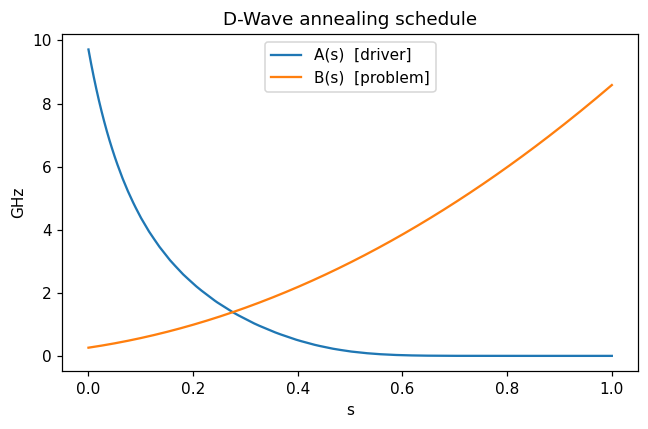

In [3]:
schedule = load_schedule(SCHEDULE_PATH)
s_grid = np.linspace(0, 1, 200)
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(s_grid, schedule.A(s_grid), label="A(s)  [driver]")
ax.plot(s_grid, schedule.B(s_grid), label="B(s)  [problem]")
ax.set_xlabel("s"); ax.set_ylabel("GHz"); ax.legend(); ax.set_title("D-Wave annealing schedule")
fig.tight_layout(); plt.show()

beta (15 mK) = 0.5092 ns


             tau=2: final P(|0>)=0.9761, final entropy=0.1127, final Omega=-4.3096


            tau=10: final P(|0>)=0.9953, final entropy=0.0301, final Omega=-4.3115


 tau=inf (unitary): final P(|0>)=0.9997, final entropy=0.0000, final Omega=-4.2909


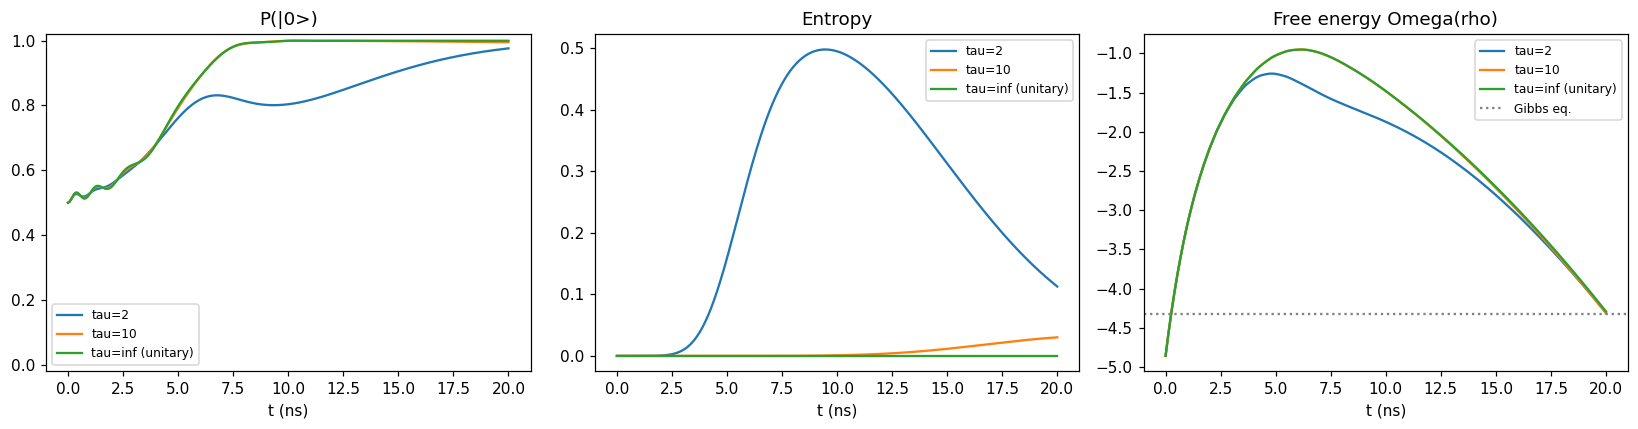

In [4]:
def run_1q_bath(H, t_anneal, tau, beta, n_points=300):
    rho0 = np.array([[0.5, 0.5], [0.5, 0.5]], dtype=complex)  # |+><+| (driver ground state)
    if np.isfinite(tau):
        diss = lambda t, rho, h: bath_dissipator(rho, h, beta, tau)
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), dissipator=diss, n_points=n_points)
    else:
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), n_points=n_points)
    p0 = np.array([np.real(r[0, 0]) for r in res.rho])
    ent = np.array([entropy(r) for r in res.rho])
    omega = np.array([free_energy(r, H(t), beta) for t, r in zip(res.t, res.rho)])
    return res.t, p0, ent, omega

t_anneal_1q = 20.0
H_1q = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=t_anneal_1q)
beta_bath = beta_from_kelvin(0.015)  # 15 mK
print(f"beta (15 mK) = {beta_bath:.4f} ns")

taus_1q = [2.0, 10.0, np.inf]
labels = {2.0: "tau=2", 10.0: "tau=10", np.inf: "tau=inf (unitary)"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for tau in taus_1q:
    t, p0, ent, omega = run_1q_bath(H_1q, t_anneal_1q, tau, beta_bath)
    axes[0].plot(t, p0, label=labels[tau])
    axes[1].plot(t, ent, label=labels[tau])
    axes[2].plot(t, omega, label=labels[tau])
    print(f"{labels[tau]:>18}: final P(|0>)={p0[-1]:.4f}, final entropy={ent[-1]:.4f}, final Omega={omega[-1]:.4f}")
h1_final = H_1q(t_anneal_1q)
omega_eq_1q = free_energy(gibbs_state(h1_final, beta_bath), h1_final, beta_bath)
axes[2].axhline(omega_eq_1q, color="gray", linestyle=":", label="Gibbs eq.")
axes[0].set_title("P(|0>)"); axes[0].legend(fontsize=8); axes[0].set_ylim(-0.02, 1.02)
axes[1].set_title("Entropy"); axes[1].legend(fontsize=8)
axes[2].set_title("Free energy Omega(rho)"); axes[2].legend(fontsize=8)
for a in axes: a.set_xlabel("t (ns)")
fig.tight_layout(); plt.show()

## 3. $t_{\text{anneal}} \times \tau$ sweep (1 qubit, bath, real D-Wave schedule)

Since the bath's target is the Gibbs state rather than a fixed pure state,
dissipation doesn't only compete with reaching the answer the way a
fixed-energy dissipator would -- sweep across anneal time and relaxation
rate to see where it helps or hurts.

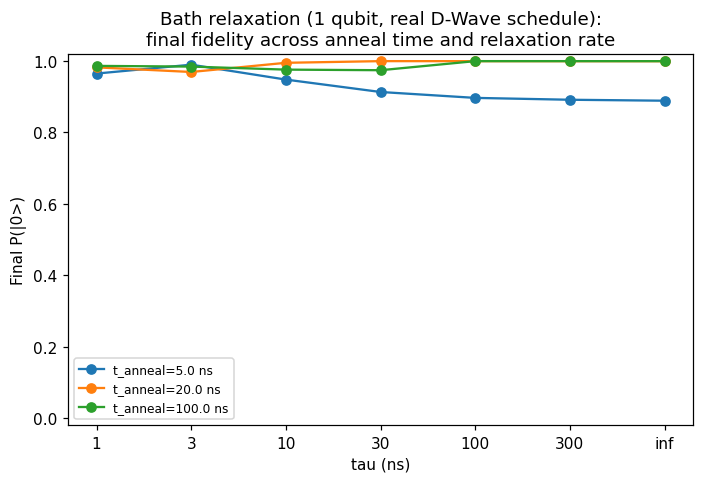

For a fast (diabatic) anneal, strong dissipation can reach HIGHER fidelity than
the pure unitary limit -- unlike a fixed-energy dissipator, whose target is a
pure state and so can only compete with, never help, reaching one.


In [5]:
tau_sweep = [1.0, 3.0, 10.0, 30.0, 100.0, 300.0, np.inf]
labels_sweep = [f"{t:g}" if np.isfinite(t) else "inf" for t in tau_sweep]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for t_anneal in [5.0, 20.0, 100.0]:
    H_sweep = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=t_anneal)
    finals = [run_1q_bath(H_sweep, t_anneal, tau, beta_bath, n_points=120)[1][-1] for tau in tau_sweep]
    ax.plot(labels_sweep, finals, marker="o", label=f"t_anneal={t_anneal} ns")
ax.set_xlabel("tau (ns)"); ax.set_ylabel("Final P(|0>)")
ax.set_title("Bath relaxation (1 qubit, real D-Wave schedule):\nfinal fidelity across anneal time and relaxation rate")
ax.legend(fontsize=8); ax.set_ylim(-0.02, 1.02)
fig.tight_layout(); plt.show()

print("For a fast (diabatic) anneal, strong dissipation can reach HIGHER fidelity than")
print("the pure unitary limit -- unlike a fixed-energy dissipator, whose target is a")
print("pure state and so can only compete with, never help, reaching one.")

## 4. Why can a *shorter* anneal beat a longer one at the same tau? A moving target

Section 3's sweep showed something that looks backwards at first:
`t_anneal=20` can end up with a *higher* final `P(|0>)` than `t_anneal=100`
at the same `tau`. The resolution is that the unitary part and the
dissipative part of the dynamics are chasing two genuinely different
targets:

* **annealing (unitary)** pursues the *instantaneous ground state* of
  $H(t)$ -- a pure state, ideal target $P(|0\rangle)=1$;
* **`bath_dissipator`** pursues the *instantaneous Gibbs state* of that
  same $H(t)$ at the bath's temperature -- a mixed (thermal) state, whose
  $P(|0\rangle)$ rises with $s=t/t_{\text{anneal}}$ but only reaches
  $\approx 0.9875$ at $s=1$ for this schedule/temperature, never $1$,
  because the bath temperature is finite (residual thermal population in
  the excited state, however small).

"Same `tau`" is a fixed *rate* toward that moving target, not a fixed
*outcome* -- a longer anneal gives the bath strictly more absolute time to
pull the trajectory toward wherever that target currently sits, which for
most of the schedule is *below* its final value.

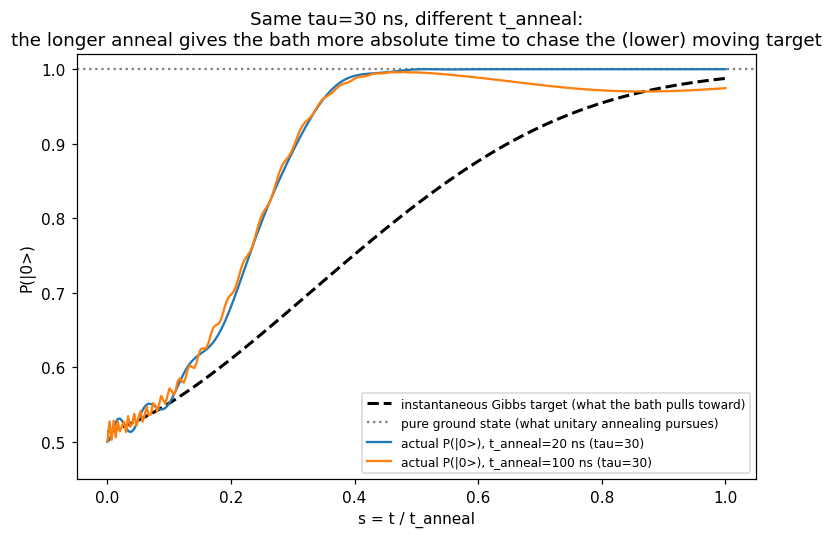

Bath's true final target at s=1: P(|0>) = 0.9875  (not 1.0 -- finite bath temperature)

    s | instant-Gibbs target |  actual, t_anneal=20 |  actual, t_anneal=100


 0.00 |               0.5132 |               0.5000 |                0.5000


 0.25 |               0.6450 |               0.7979 |                0.8057


 0.50 |               0.8184 |               0.9998 |                0.9956


 0.75 |               0.9401 |               0.9999 |                0.9746


 0.90 |               0.9754 |               0.9999 |                0.9703


 1.00 |               0.9875 |               0.9999 |                0.9745


In [6]:
H_ref_s = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=1.0)  # t_anneal=1 -> t IS s directly
s_grid_target = np.linspace(0, 1, 100)
gibbs_target_curve = np.array([gibbs_state(H_ref_s(s), beta_bath)[0, 0].real for s in s_grid_target])

tau_mt = 30.0
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(s_grid_target, gibbs_target_curve, "k--", lw=2,
        label="instantaneous Gibbs target (what the bath pulls toward)")
ax.axhline(1.0, color="gray", linestyle=":",
           label="pure ground state (what unitary annealing pursues)")

for t_anneal_mt in [20.0, 100.0]:
    H_mt = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=t_anneal_mt)
    t, p0, ent, omega = run_1q_bath(H_mt, t_anneal_mt, tau_mt, beta_bath, n_points=300)
    ax.plot(t / t_anneal_mt, p0, label=f"actual P(|0>), t_anneal={t_anneal_mt:g} ns (tau={tau_mt:g})")

ax.set_xlabel("s = t / t_anneal"); ax.set_ylabel("P(|0>)")
ax.set_title(f"Same tau={tau_mt:g} ns, different t_anneal:\nthe longer anneal gives the bath more absolute time to chase the (lower) moving target")
ax.legend(fontsize=8, loc="lower right"); ax.set_ylim(0.45, 1.02)
fig.tight_layout(); plt.show()

print(f"Bath's true final target at s=1: P(|0>) = {gibbs_target_curve[-1]:.4f}  (not 1.0 -- finite bath temperature)")
print()
print(f"{'s':>5} | {'instant-Gibbs target':>20} | {'actual, t_anneal=20':>20} | {'actual, t_anneal=100':>21}")
for s_chk in [0.0, 0.25, 0.5, 0.75, 0.9, 1.0]:
    H20 = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=20.0)
    H100 = hamiltonian_1qubit(schedule, h1=-1.0, t_anneal=100.0)
    _, p0_20, _, _ = run_1q_bath(H20, 20.0, tau_mt, beta_bath, n_points=300)
    _, p0_100, _, _ = run_1q_bath(H100, 100.0, tau_mt, beta_bath, n_points=300)
    idx20 = int(round(s_chk * (len(p0_20) - 1)))
    idx100 = int(round(s_chk * (len(p0_100) - 1)))
    target_val = gibbs_state(H_ref_s(s_chk), beta_bath)[0, 0].real
    print(f"{s_chk:5.2f} | {target_val:20.4f} | {p0_20[idx20]:20.4f} | {p0_100[idx100]:21.4f}")

Reading the plot and table together: both trajectories race ahead of
the instantaneous Gibbs target early on (the unitary/adiabatic part wins
that phase, since the minimum gap for this problem closes around
$s\approx 0.3$-$0.5$). Past that point, `t_anneal=20` only has a handful of
nanoseconds left -- at `tau=30` that is well under one relaxation time, not
enough for the bath to noticeably pull the "overshoot" back down before the
anneal ends. `t_anneal=100` has ~5x more absolute time in that same
window -- enough for the bath to visibly drag `P(|0>)` back down toward the
still-rising-but-lower target, and it doesn't fully recover by $s=1$.

This is why the effect is strongest for `tau` comparable to the *leftover*
time after the gap closes, not for very strong dissipation (locked to the
target from the start, so there is no overshoot to lose) or very weak
dissipation (negligible pull either way).

## 5. Extending to N qubits

`seaqt.operators` builds Pauli operators on any qubit of an $n$-qubit
register via Kronecker products, and assembles the (D-Wave-convention)
Ising Hamiltonian. `bath_dissipator` and `evolve` never assumed 2x2 --
they work unmodified for any Hilbert-space dimension.

In [7]:
H2 = ising_hamiltonian(2, h=[0.6, -0.4], J={(0, 1): 0.5}, A=1.0, B=0.7)
print("2-qubit Hamiltonian, shape", H2.shape, ", Hermitian:", np.allclose(H2, H2.conj().T))
print(H2.real)

rho2 = hermitize(np.eye(4, dtype=complex) / 4 + 0.05 * np.random.default_rng(0).normal(size=(4, 4)))
rho2 /= np.trace(rho2).real
D2 = bath_dissipator(rho2, H2, beta=1.0, tau=1.0)
print(f"\n2-qubit bath dissipator: Tr(D)={np.trace(D2):.2e}  (want 0)")

2-qubit Hamiltonian, shape (4, 4) , Hermitian: True
[[ 0.245 -0.5   -0.5    0.   ]
 [-0.5    0.175  0.    -0.5  ]
 [-0.5    0.    -0.525 -0.5  ]
 [ 0.    -0.5   -0.5    0.105]]

2-qubit bath dissipator: Tr(D)=-5.55e-17+0.00e+00j  (want 0)


## 6. Two qubits -- real D-Wave schedule + local SEAQT relaxation

The main result this repo is built around: two coupled qubits, the real
QPU annealing schedule, each qubit relaxing *locally* via
`local_seaqt_dissipator` (section 9 has the full derivation/validation).

The initial state is a slightly-thermalized driver state
(`gibbs_state(H(0), beta_init)`, `beta_init` large enough to be ~T=0 in
practice) rather than the exact pure ground state, and the linear bias
$h$ is genuinely asymmetric -- see section 8 for why. `tau_A=tau_B \ge 10`
ns is used here deliberately: section 9 shows positivity of $\rho$ can be
violated for smaller, more aggressive `tau` with this schedule.

Ground state: |10>, gap=7.7277


      tau_A=tau_B=10: final distribution P(|00>)=0.0227, P(|01>)=0.0186, P(|10>)=0.9144, P(|11>)=0.0443


      tau_A=tau_B=30: final distribution P(|00>)=0.0097, P(|01>)=0.0076, P(|10>)=0.9651, P(|11>)=0.0175


tau = inf (unitary only): final distribution P(|00>)=0.0008, P(|01>)=0.0046, P(|10>)=0.9880, P(|11>)=0.0066


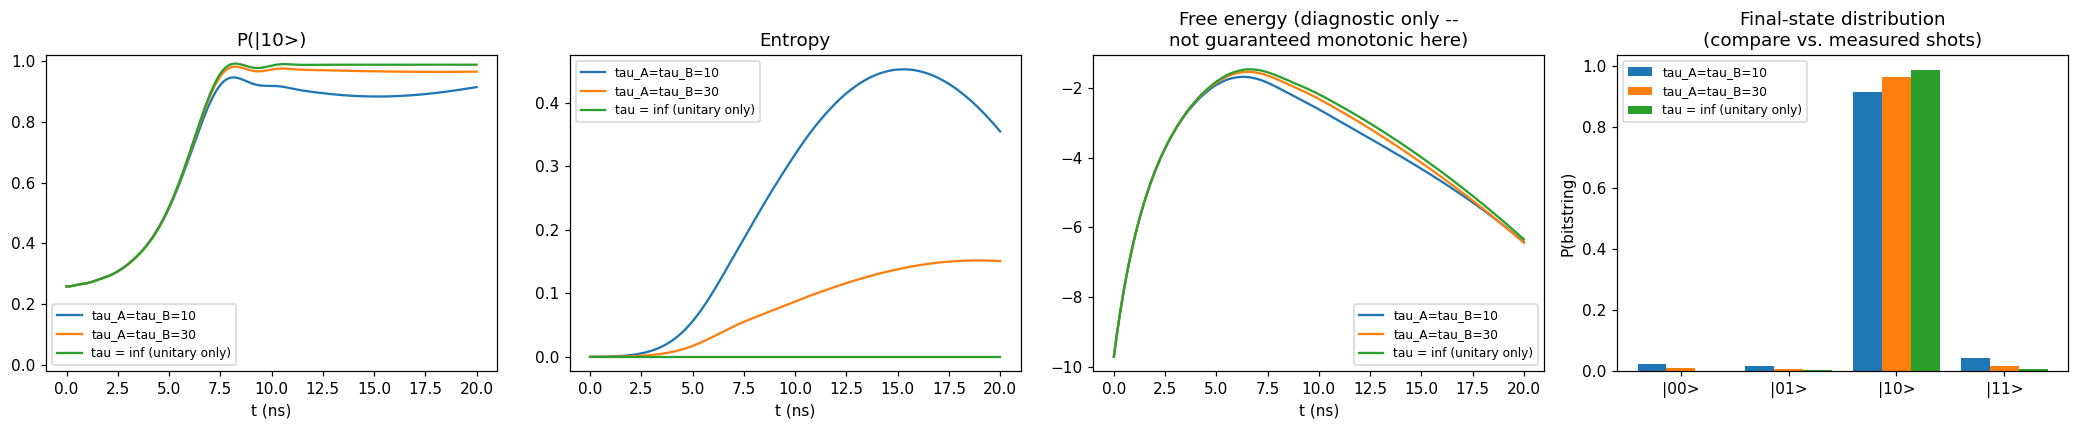

In [8]:
H_BIAS_2Q = [0.6, -0.4]
J12 = 0.5
BETA_INIT = 5.0

def run_2q_local_seaqt(H, t_anneal, tau, beta_r, n_points=250):
    rho0 = gibbs_state(H(0.0), BETA_INIT)
    if np.isfinite(tau):
        diss = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_r, tau_a=tau, tau_b=tau)
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), dissipator=diss, n_points=n_points)
    else:
        res = evolve(rho0, hamiltonian=H, t_span=(0, t_anneal), n_points=n_points)
    _, v = np.linalg.eigh(H(t_anneal))
    ground_vec = v[:, 0]
    p_ground = np.array([np.real(ground_vec.conj() @ r @ ground_vec) for r in res.rho])
    ent = np.array([entropy(r) for r in res.rho])
    omega = np.array([free_energy(r, H(t), beta_r) for t, r in zip(res.t, res.rho)])
    final_dist = population_distribution(res.rho[-1])
    return res.t, p_ground, ent, omega, final_dist

t_anneal_2q = 20.0
H_2q = hamiltonian_nqubit(schedule, h=H_BIAS_2Q, J={(0, 1): J12}, t_anneal=t_anneal_2q)
h2_final = H_2q(t_anneal_2q)
w2, v2 = np.linalg.eigh(h2_final)
labels_bits_2q = basis_labels(2)
ground_idx_2q = int(np.argmax(np.abs(v2[:, 0])))
print(f"Ground state: {labels_bits_2q[ground_idx_2q]}, gap={w2[1]-w2[0]:.4f}")

taus_2q = [10.0, 30.0, np.inf]
labels_2q = {10.0: "tau_A=tau_B=10", 30.0: "tau_A=tau_B=30", np.inf: "tau = inf (unitary only)"}
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
final_dists_2q = {}
for tau in taus_2q:
    t, p_ground, ent, omega, final_dist = run_2q_local_seaqt(H_2q, t_anneal_2q, tau, beta_bath)
    final_dists_2q[tau] = final_dist
    axes[0].plot(t, p_ground, label=labels_2q[tau])
    axes[1].plot(t, ent, label=labels_2q[tau])
    axes[2].plot(t, omega, label=labels_2q[tau])
    print(f"{labels_2q[tau]:>20}: final distribution " +
          ", ".join(f"P({lbl})={p:.4f}" for lbl, p in zip(labels_bits_2q, final_dist)))
axes[0].set_title(f"P({labels_bits_2q[ground_idx_2q]})"); axes[0].legend(fontsize=8); axes[0].set_ylim(-0.02, 1.02)
axes[1].set_title("Entropy"); axes[1].legend(fontsize=8)
# Note: unlike bath_dissipator, local_seaqt_dissipator does NOT guarantee Omega
# decreases monotonically toward the global Gibbs state -- diagnostic only.
axes[2].set_title("Free energy (diagnostic only --\nnot guaranteed monotonic here)"); axes[2].legend(fontsize=8)
for a in axes[:3]: a.set_xlabel("t (ns)")

# Final-state distribution, grouped by tau -- the panel to overlay against a
# measured bitstring/shot histogram from real hardware (rho is represented in
# the computational/Z basis throughout, the same basis a QPU measures in).
x = np.arange(len(labels_bits_2q))
width = 0.8 / len(taus_2q)
for i, tau in enumerate(taus_2q):
    axes[3].bar(x + (i - (len(taus_2q) - 1) / 2) * width, final_dists_2q[tau], width, label=labels_2q[tau])
axes[3].set_xticks(x); axes[3].set_xticklabels(labels_bits_2q)
axes[3].set_ylabel("P(bitstring)"); axes[3].set_title("Final-state distribution\n(compare vs. measured shots)")
axes[3].legend(fontsize=8)

fig.tight_layout(); plt.show()

## 7. What if there's no bias at all? A genuinely undecided problem (`h=[0,0]`)

Section 6's problem was deliberately asymmetric (`h=[0.6,-0.4]`) so the
ground state is unique. What does the exact same real-schedule simulation
predict if the linear bias is removed entirely, keeping only the
antiferromagnetic coupling `J12=0.5`? The coupling still favors
*anti-aligned* qubits over aligned ones, but nothing is left to break the
tie between the two anti-aligned bitstrings ($|01\rangle$ vs.
$|10\rangle$) -- a genuinely *undecided* problem, not just a small-gap
one.

Final H eigenvalues: [-2.1466 -2.1466  2.1466  2.1466]  -- an exactly two-fold degenerate ground doublet
eigh's 'ground eigenvector': [-0.      0.6686 -0.7436 -0.    ]
  -- an ARBITRARY superposition of |01> and |10>, not either bitstring individually.
  P(ground) tracked against THIS vector isn't physically meaningful here -- the
  final-distribution bar chart below is the diagnostic that actually makes sense.



      tau_A=tau_B=10: P(|00>)=0.0251, P(|01>)=0.4749, P(|10>)=0.4749, P(|11>)=0.0251


      tau_A=tau_B=30: P(|00>)=0.0094, P(|01>)=0.4906, P(|10>)=0.4906, P(|11>)=0.0094


tau = inf (unitary only): P(|00>)=0.0025, P(|01>)=0.4975, P(|10>)=0.4975, P(|11>)=0.0025


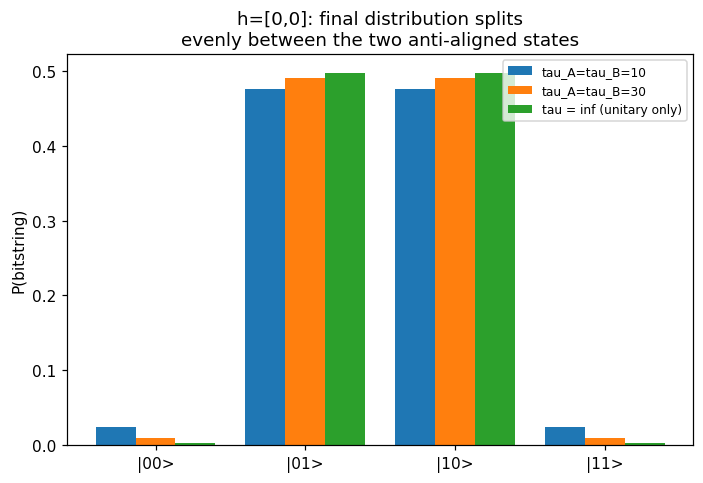

In [9]:
H_undecided = hamiltonian_nqubit(schedule, h=[0.0, 0.0], J={(0, 1): J12}, t_anneal=t_anneal_2q)
h_final_undecided = H_undecided(t_anneal_2q)
w_u, v_u = np.linalg.eigh(h_final_undecided)
print(f"Final H eigenvalues: {np.round(w_u, 4)}  -- an exactly two-fold degenerate ground doublet")
print(f"eigh's 'ground eigenvector': {np.round(v_u[:, 0].real, 4)}")
print("  -- an ARBITRARY superposition of |01> and |10>, not either bitstring individually.")
print("  P(ground) tracked against THIS vector isn't physically meaningful here -- the")
print("  final-distribution bar chart below is the diagnostic that actually makes sense.\n")

final_dists_undecided = {}
for tau in taus_2q:
    _, _, _, _, final_dist = run_2q_local_seaqt(H_undecided, t_anneal_2q, tau, beta_bath)
    final_dists_undecided[tau] = final_dist
    print(f"{labels_2q[tau]:>20}: " + ", ".join(f"P({lbl})={p:.4f}" for lbl, p in zip(labels_bits_2q, final_dist)))

fig, ax = plt.subplots(figsize=(6.5, 4.5))
x = np.arange(len(labels_bits_2q))
width = 0.8 / len(taus_2q)
for i, tau in enumerate(taus_2q):
    ax.bar(x + (i - (len(taus_2q) - 1) / 2) * width, final_dists_undecided[tau], width, label=labels_2q[tau])
ax.set_xticks(x); ax.set_xticklabels(labels_bits_2q)
ax.set_ylabel("P(bitstring)")
ax.set_title("h=[0,0]: final distribution splits\nevenly between the two anti-aligned states")
ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

As expected: population splits almost evenly between $|01\rangle$
and $|10\rangle$ (both preferred equally by the antiferromagnetic
coupling, with no $h_i$ left to break the tie), while $|00\rangle$ and
$|11\rangle$ (aligned -- genuinely disfavored by $J_{12}>0$, not a
degenerate case) stay small. The residual weight on that "wrong" pair
shrinks with weaker dissipation, the same mechanism as section 6's biased
problem.

The `eigh`-selected "ground eigenvector" printed above is worth a second
look: it's neither $|01\rangle$ nor $|10\rangle$, but some arbitrary
mix -- the same degenerate-eigenspace ambiguity that section 8
investigates next, there for `local_seaqt_dissipator`'s *numerical*
robustness; here, for what it even means to ask "$P(\text{ground})$?" of
a genuinely tied problem.

## 8. Degenerate states and `local_seaqt_dissipator`

Section 9 will reuse the same "does it stay numerically well-behaved"
rigor as sections 1 and 9(a), but the failure mode worth testing here is
*different* from the one bath relaxation had to survive.

`bath_dissipator` computes $\ln\rho$ on the **full** $2^n\times2^n$ $\rho$.
For 2+ qubits, an exactly pure $\rho$ has a degenerate zero-eigenvalue
eigenspace of dimension $d-1\ge2$ -- `eigh` picks an essentially arbitrary
basis there, which is what made the old (removed) fixed-energy dissipator
fragile.

`local_seaqt_dissipator` instead computes $\ln\rho_J$ on each qubit's
**reduced** $2\times2$ state ($\rho_A=\mathrm{Tr}_B(\rho)$, etc. -- see
`_subsystem_dissipator` in `seaqt/local_seaqt.py`). A $2\times2$ matrix
can only be degenerate one way: both eigenvalues equal, i.e. $\rho_J$ is
*exactly proportional to the identity* -- a **maximally mixed single
qubit**. That case is actually safe by construction ($\ln(cI)=\ln(c)\,I$
is basis-independent, whichever eigenbasis `eigh` happens to return), so
purity of the *full* state alone -- which was the dangerous case for
`bath_dissipator` -- isn't automatically dangerous here.

The genuinely analogous danger for `local_seaqt_dissipator` is a
**maximally *entangled*** full pure state: then the *reduced* single-qubit
states are exactly $I/2$, and (unlike the plain-mixed case above) the
*locally perceived Hamiltonian* $H_J$ can itself become degenerate too --
worth checking directly rather than assuming it inherits `bath_dissipator`'s
good behavior for free.

**Setup: `h=[0,0]`, the symmetric antiferromagnetic problem.** With no
linear bias, $H=\tfrac{B}{2}J\,\sigma_z^{(0)}\sigma_z^{(1)}$ (pure
"problem" term, $A=0$) has an *exactly* two-fold degenerate ground doublet
spanned by $|01\rangle$ and $|10\rangle$.

In [10]:
H_sym = ising_hamiltonian(2, h=[0, 0], J={(0, 1): 1.0}, A=0.0, B=1.0)
w_sym, v_sym = np.linalg.eigh(H_sym)
print(f"H_sym eigenvalues: {np.round(w_sym, 4)}  (two-fold degenerate ground doublet)")

# The product ground state eigh actually returns here (H_sym is already diagonal,
# so there's no arbitrary-basis ambiguity in this particular trivial case):
psi_product = v_sym[:, 0]
rho_product = np.outer(psi_product, psi_product.conj())
rho_A_product = reduced_state(rho_product, keep=0)
print(f"eigh's ground state: {np.round(psi_product.real, 3)} (a computational basis state)")
print(f"  reduced rho_A eigenvalues: {np.round(np.linalg.eigvalsh(rho_A_product), 4)}  <- pure, NOT degenerate")

# The maximally-ENTANGLED combination within that same degenerate ground doublet:
psi_bell = np.zeros(4, dtype=complex)
psi_bell[1] = psi_bell[2] = 1 / np.sqrt(2)  # (|01> + |10>) / sqrt(2)
rho_bell = np.outer(psi_bell, psi_bell.conj())
rho_A_bell = reduced_state(rho_bell, keep=0)
print(f"\n(|01>+|10>)/sqrt(2) -- also an exact ground state (same energy, {w_sym[0]:.4f})")
print(f"  reduced rho_A eigenvalues: {np.round(np.linalg.eigvalsh(rho_A_bell), 6)}  <- exactly I/2, degenerate!")

H_sym eigenvalues: [-0.5 -0.5  0.5  0.5]  (two-fold degenerate ground doublet)
eigh's ground state: [0. 1. 0. 0.] (a computational basis state)
  reduced rho_A eigenvalues: [0. 1.]  <- pure, NOT degenerate

(|01>+|10>)/sqrt(2) -- also an exact ground state (same energy, -0.5000)
  reduced rho_A eigenvalues: [0.5 0.5]  <- exactly I/2, degenerate!


Both are exact, valid, pure ground states of the same degenerate
doublet -- which one you'd get from `eigh` on a less trivial (non-diagonal)
Hamiltonian is itself arbitrary. So test `local_seaqt_dissipator`'s
sensitivity to infinitesimal perturbations at **both**, the way section
1's Gibbs-state check and the old bath_dissipator check both did.

In [11]:
rng = np.random.default_rng(0)
print("Maximally-entangled pure state (degenerate reduced states), local_seaqt_dissipator:")
prev_D = None
for eps in [0, 1e-9, 1e-8, 1e-6]:
    perturb = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
    rho = rho_bell + eps * perturb
    rho = rho / np.trace(rho).real
    D = local_seaqt_dissipator(rho, H_sym, beta_r=1.5, tau_a=1.0, tau_b=1.0)
    change = "" if prev_D is None else f", ||delta D|| = {np.max(np.abs(D - prev_D)):.6f}"
    print(f"  eps={eps:.0e}: ||D||_max = {np.max(np.abs(D)):.6f}{change}")
    prev_D = D

print("\nProduct pure state (non-degenerate reduced states), local_seaqt_dissipator:")
prev_D = None
rng = np.random.default_rng(0)
for eps in [0, 1e-9, 1e-8, 1e-6]:
    perturb = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
    rho = rho_product + eps * perturb
    rho = rho / np.trace(rho).real
    D = local_seaqt_dissipator(rho, H_sym, beta_r=1.5, tau_a=1.0, tau_b=1.0)
    change = "" if prev_D is None else f", ||delta D|| = {np.max(np.abs(D - prev_D)):.6f}"
    print(f"  eps={eps:.0e}: ||D||_max = {np.max(np.abs(D)):.6f}{change}")
    prev_D = D

Maximally-entangled pure state (degenerate reduced states), local_seaqt_dissipator:
  eps=0e+00: ||D||_max = 0.000000
  eps=1e-09: ||D||_max = 0.000000, ||delta D|| = 0.000000
  eps=1e-08: ||D||_max = 0.000000, ||delta D|| = 0.000000
  eps=1e-06: ||D||_max = 0.000001, ||delta D|| = 0.000001

Product pure state (non-degenerate reduced states), local_seaqt_dissipator:
  eps=0e+00: ||D||_max = 0.000000
  eps=1e-09: ||D||_max = 0.000000, ||delta D|| = 0.000000
  eps=1e-08: ||D||_max = 0.000001, ||delta D|| = 0.000001
  eps=1e-06: ||D||_max = 0.000030, ||delta D|| = 0.000031


**Stable in both cases** -- no discontinuity, `||D||` grows smoothly
with `eps` starting from either exact pure state. This isn't a coincidence:
whichever orthonormal basis `eigh` happens to return for a *degenerate*
$2\times2$ eigenspace, the matrix there is exactly $cI$, and $\ln(cI)=\ln(c)\,I$
comes out identical regardless of that choice -- there's no ambiguous
direction for the perturbation to expose, unlike the $\ge2$-dimensional
degenerate null space a pure *full* state has at $d\ge4$.

Now the schedule-level pathological test from before, adapted to
`local_seaqt_dissipator`: the fully time-dependent `h=[0,0]` problem, whose
ground doublet stays exactly degenerate through to the end of the anneal,
starting from the maximally-entangled pure state above.

In [12]:
H_pathological = lambda t: ising_hamiltonian(
    2, h=[0, 0], J={(0, 1): 1.0}, A=(1 - np.clip(t / 20.0, 0, 1)) * 1.0, B=np.clip(t / 20.0, 0, 1)
)
diss_pathological = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_r=1.5, tau_a=2.0, tau_b=2.0)
try:
    res_path = evolve(rho_bell, hamiltonian=H_pathological, t_span=(0, 20.0), dissipator=diss_pathological, n_points=50)
    traces = [np.real(np.trace(r)) for r in res_path.rho]
    min_eig_path = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_path.rho)
    print(f"Integration succeeded. trace range=[{min(traces):.6f}, {max(traces):.6f}], min eigenvalue over trajectory={min_eig_path:.6f}")
except RuntimeError as e:
    print(f"Integration failed (fast and with a clear error, not a silent hang): {e}")

Integration succeeded. trace range=[1.000000, 1.000000], min eigenvalue over trajectory=-0.074967


**Result: it also succeeded** -- no hang, no crash, exact trace
conservation throughout. The negative minimum eigenvalue printed above
isn't a *new* failure mode, though -- it's `local_seaqt_dissipator`'s
**already-documented positivity limitation** from section 9 showing up
here too (`tau=2` is deliberately the aggressive value section 9 flags as
unsafe). The degenerate-eigenbasis question this section actually set out
to test -- discontinuity under perturbation -- came back clean in both the
static check above and this dynamic one.

## 9. `local_seaqt_dissipator`: validation, and a real limitation (positivity)

Same rigor as section 1, now for the dissipator used in section 6. Three
checks, cross-checked once (not repeated here) to machine precision
($\sim10^{-16}$) against a literal port of the reference implementation
this was adapted from -- see `tests/test_local_seaqt.py`.

**(a) $D_J$ vanishes at its own local Gibbs fixed point.** Algebraic
identity (expand $\langle f\rangle_J$ and it cancels exactly) -- the same
kind of check as section 1's "vanishes at the Gibbs state".

In [13]:
rng = np.random.default_rng(3)
h_demo4 = hermitize(rng.normal(size=(4, 4)) + 1j * rng.normal(size=(4, 4)))
m = rng.normal(size=(2, 2)) + 1j * rng.normal(size=(2, 2))
rho_b_arbitrary = hermitize(m @ m.conj().T); rho_b_arbitrary /= np.trace(rho_b_arbitrary).real

h_a_actual = locally_perceived_operator(h_demo4, rho_b_arbitrary, target_qubit=0)
rho_a_eq = gibbs_state(h_a_actual, beta=1.7)
d_a = _subsystem_dissipator(rho_a_eq, h_a_actual, beta_r=1.7)
print(f"max|D_A| at its own local Gibbs state = {np.max(np.abs(d_a)):.3e}  (want ~0)")

max|D_A| at its own local Gibbs state = 1.541e-16  (want ~0)


**(b) Trace conservation and positivity, well-behaved `tau`.**

In [14]:
diss_ok = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_r=1.5, tau_a=10.0, tau_b=10.0)
rho0_check = gibbs_state(H2, beta=5.0)
res_ok = evolve(rho0_check, hamiltonian=lambda t: H2, t_span=(0, 20), dissipator=diss_ok, n_points=150)
traces = [np.real(np.trace(r)) for r in res_ok.rho]
min_eig_ok = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_ok.rho)
print(f"trace range: [{min(traces):.8f}, {max(traces):.8f}]  (want ~1)")
print(f"min eigenvalue over trajectory: {min_eig_ok:.3e}  (want >= ~-1e-6)")

trace range: [1.00000000, 1.00000000]  (want ~1)
min eigenvalue over trajectory: 2.048e-05  (want >= ~-1e-6)


**(c) The limitation: positivity is NOT guaranteed for strong dissipation.**
Eq. 15 is derived in the paper as an *approximation* -- "[e]xpanding the
determinants and using the fact that the ratio of the inner products
$\epsilon=P_{SJ}/P_R$ is very small due to the large size of $R$" (the
effective reservoir is assumed to dominate over the local "system"). The
paper proves neither positivity preservation nor an explicit validity
range for $\tau_A,\tau_B,\beta_R$. Confirmed below on the real schedule
used in section 6: `tau=10` (section 6's default) stays essentially
positive; `tau=2` (aggressive) does not -- and this is *not* an
integration-tolerance artifact (unchanged at `rtol=1e-11` vs. the default
`1e-9`, tested separately).

In [15]:
rho0_2q = gibbs_state(H_2q(0.0), BETA_INIT)  # matches section 6's initial state exactly
for tau_test in [10.0, 2.0]:
    diss_test = lambda t, rho, h: local_seaqt_dissipator(rho, h, beta_bath, tau_a=tau_test, tau_b=tau_test)
    res_test = evolve(rho0_2q, hamiltonian=H_2q, t_span=(0, 20.0), dissipator=diss_test, n_points=150)
    min_eig_test = min(np.linalg.eigvalsh(hermitize(r)).min() for r in res_test.rho)
    print(f"tau={tau_test:>4}: min eigenvalue over trajectory = {min_eig_test:+.6f}")

print("\nThis is why section 6 defaults to tau_A=tau_B >= 10 ns for this schedule --")
print("the reliably well-behaved choice, not a proof that nothing smaller ever works.")

tau=10.0: min eigenvalue over trajectory = -0.000000


tau= 2.0: min eigenvalue over trajectory = -0.068397

This is why section 6 defaults to tau_A=tau_B >= 10 ns for this schedule --
the reliably well-behaved choice, not a proof that nothing smaller ever works.


## Next steps

- Push past 2 qubits -- `bath_dissipator`, `evolve`, and
  `seaqt.operators.ising_hamiltonian` already work for any finite
  Hilbert-space dimension $d=2^n$; going further is a runtime/tooling
  question, not a physics one. `local_seaqt_dissipator` is currently
  2-qubit-specific (eq. 7 generalizes to $M$ subsystems, but the
  implementation here only covers the bipartite $M=2$ case).
- Sweep $t_{\text{anneal}} \times \tau$ for the 2-qubit case the way
  section 3 already does for 1 qubit.
- Explore an intentionally (near-)degenerate multi-qubit ground-state
  manifold with a stiff-aware integration strategy (analytic Jacobian or a
  proper implicit solver) robust enough to handle the small-minimum-gap
  regime demonstrated in section 8.
- Investigate a positivity-preserving fix or bound for
  `local_seaqt_dissipator` (section 9) -- e.g. deriving beyond the paper's
  small-$\epsilon$ approximation, or a metric-respecting construction
  analogous to Beretta's full determinant formula.
- Explore state- or schedule-dependent $\tau(\rho, t)$ rather than a
  constant relaxation time.
- Compare against real D-Wave hardware results for a small problem
  instance, once available.